# Bayesian search backtest

Uses Optuna to pick each next config based on the ones already scored, so it can explore wider ranges than a grid with the same budget. Same models, dates, and metrics as the grid search notebook.

## Setup

All imports live here. The notebook moves to the repo root so it uses the same config and MLflow store as `natgas tune`.

In [1]:
import logging
import os
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
os.environ["HF_HUB_DISABLE_EXPERIMENTAL_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

from natgas.config import load_settings
from natgas.forecasting.backtesting import Backtester
from natgas.forecasting.data import ForecastDataProvider
from natgas.forecasting.models.chronos.ChronosModel import ChronosModel
from natgas.forecasting.models.chronos.ChronosModelConfig import ChronosModelConfig
from natgas.forecasting.optimization import BayesianOptimizer
from natgas.forecasting.tuning import ModelPublisher, TuningConfig

# Run from the repo root so config files, mlflow.db, and mlruns/ line up
if Path.cwd().name == "experiments":
    os.chdir(Path.cwd().parent)

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
for name in ["natgas", "mlflow", "greykite", "optuna", "huggingface_hub", "transformers", "torch"]:
    logging.getLogger(name).setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Download Chronos-2 once, then stay offline so worker processes do not
# retry Hugging Face and print timeout warnings.
ChronosModel.pipeline_for(ChronosModelConfig().model_id, "cpu")
os.environ["HF_HUB_OFFLINE"] = "1"

# Greykite switches matplotlib to a file backend, so turn inline charts back on
%matplotlib inline

## Data

`ForecastDataProvider` is the only way models get data. Every as-of date gets training data up to that date and the next 5 trading days to score against. The dates are the same in both notebooks, so the results are comparable.

In [2]:
tuning = TuningConfig.from_yaml("config/tuning.yaml")
settings = load_settings()
provider = ForecastDataProvider.from_settings(settings, tuning.horizon_days, tuning.target_column)
as_of_dates = provider.backtest_dates(tuning.backtest_start, tuning.backtest_end, tuning.step_days)

first, last = provider.first_date.date(), provider.last_date.date()
print(f"prices: {first} to {last}, {len(provider.target)} trading days")
print(f"features: {provider.feature_columns}")
print(
    f"{len(as_of_dates)} as-of dates from {as_of_dates[0].date()} to {as_of_dates[-1].date()}, "
    f"{tuning.horizon_days} trading days ahead each"
)

prices: 2015-01-02 to 2026-11-18, 2989 trading days
features: ['hdd', 'cdd', 'christmas_day', 'christmas_day_pre_1', 'christmas_day_pre_2', 'christmas_day_pre_3', 'christmas_day_pre_4', 'christmas_day_post_1', 'christmas_day_post_2', 'christmas_day_post_3', 'christmas_day_post_4', 'columbus_day', 'columbus_day_pre_1', 'columbus_day_pre_2', 'columbus_day_pre_3', 'columbus_day_pre_4', 'columbus_day_post_1', 'columbus_day_post_2', 'columbus_day_post_3', 'columbus_day_post_4', 'independence_day', 'independence_day_pre_1', 'independence_day_pre_2', 'independence_day_pre_3', 'independence_day_pre_4', 'independence_day_post_1', 'independence_day_post_2', 'independence_day_post_3', 'independence_day_post_4', 'juneteenth_national_independence_day', 'juneteenth_national_independence_day_pre_1', 'juneteenth_national_independence_day_pre_2', 'juneteenth_national_independence_day_pre_3', 'juneteenth_national_independence_day_pre_4', 'juneteenth_national_independence_day_post_1', 'juneteenth_nationa

## Search space

Each model's options come from `config/tuning.yaml` (the `search_space` key) and map into that model's config class.

In [3]:
spaces = {name: settings.get("search_space") for name, settings in tuning.model_settings.items()}
pd.Series(spaces, name="search_space").to_frame()

,search_space
naive,None
gradient_boosting,"{'n_lags': {'low': 3, 'high': 20}, 'learning_rate': {'low': 0.01, 'high': 0.3, 'log': True}, 'max_depth': {'low': 2,..."
greykite,"{'history_years': {'low': 2.0, 'high': 8.0}, 'autoregression_lags': {'low': 0, 'high': 5}, 'use_holidays': [True, Fa..."
chronos,"{'context_length': {'low': 64, 'high': 2048, 'step': 64}}"


## Run the backtests

Each config is backtested on every as-of date and logged as a nested MLflow run.

In [4]:
backtester = Backtester(provider, as_of_dates, n_jobs=tuning.n_jobs)
optimizer = BayesianOptimizer(
    backtester, tuning.selection_metric, n_trials=tuning.n_trials, seed=tuning.seed
)

mlflow.set_tracking_uri(tuning.tracking_uri)
mlflow.set_experiment("natgas-bayesian-search")
with mlflow.start_run(run_name="bayesian-search-notebook") as search_run:
    mlflow.set_tag("method", "bayesian")
    mlflow.log_params(
        {
            "backtest_count": len(as_of_dates),
            "horizon_days": tuning.horizon_days,
            "n_trials": tuning.n_trials,
        }
    )
    summary = optimizer.run(tuning.model_settings)

print(f"{len(summary)} configs backtested, {len(optimizer.failed)} failed")

18 configs backtested, 0 failed


## Results

Lower is better. `skill_vs_naive` above zero means the config beats repeating the last price.

In [5]:
scores = ["mae", "rmse", "mape", "wape", "bias", "skill_vs_naive"]
columns = ["model_name", "config", *scores, "seconds"]
summary[columns].round(4)

,model_name,config,mae,rmse,mape,wape,bias,skill_vs_naive,seconds
0,naive,{},0.2462,0.3828,6.1637,6.4854,0.0001,0.0000,5.6
1,chronos,"{""context_length"": 320, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}",0.2473,0.3805,6.2213,6.5131,-0.0104,-0.0043,2.6
2,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.0178601378893971, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"":...",0.2481,0.3893,6.2063,6.5340,-0.0049,-0.0075,2.1
3,chronos,"{""context_length"": 768, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}",0.2490,0.3923,6.2003,6.5588,-0.0095,-0.0113,14.1
4,chronos,"{""context_length"": 1280, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}",0.2491,0.3916,6.2246,6.5601,-0.0109,-0.0115,4.5
5,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.020589728197687916, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf...",0.2493,0.3929,6.2103,6.5662,-0.0105,-0.0125,1.9
6,chronos,"{""context_length"": 1536, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}",0.2500,0.3912,6.2574,6.5859,-0.0168,-0.0155,5.0
7,chronos,"{""context_length"": 1984, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}",0.2512,0.3933,6.2628,6.6174,-0.0219,-0.0203,5.9
8,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.02692655251486473, ""max_depth"": 5, ""max_iter"": 200, ""min_samples_leaf""...",0.2558,0.3977,6.4084,6.7389,-0.0105,-0.0391,3.1
9,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.14447746112718687, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf""...",0.2603,0.4180,6.4856,6.8563,0.0068,-0.0572,1.8


## Best config per model

In [6]:
best = optimizer.best_by_model()
best_table = pd.DataFrame(
    {name: {**report.metrics(), "config": report.config.to_json()} for name, report in best.items()}
).T.sort_values("mae")
best_table

,mae,rmse,mape,wape,bias,config
naive,0.246219,0.382759,6.163686,6.485441,0.000065,{}
chronos,0.24727,0.380546,6.221319,6.513139,-0.010368,"{""context_length"": 320, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}"
gradient_boosting,0.248062,0.389308,6.206251,6.53398,-0.004944,"{""l2_regularization"": 0.0, ""learning_rate"": 0.0178601378893971, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"":..."
greykite,0.308878,0.449018,8.048632,8.135883,0.006282,"{""auto_changepoints"": false, ""autoregression_lags"": 1, ""fit_algorithm"": ""ridge"", ""history_years"": 6.850384088698767,..."


## Error by model and by days ahead

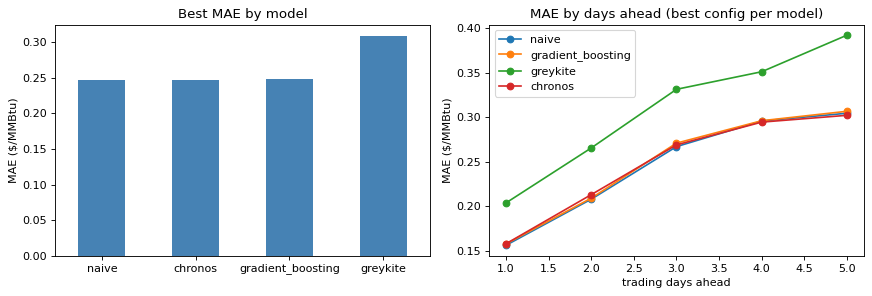

In [7]:
by_step = pd.DataFrame({name: report.metrics_by_step()["mae"] for name, report in best.items()})

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), dpi=80)
best_table["mae"].astype(float).plot.bar(ax=left, color="steelblue")
left.set_title("Best MAE by model")
left.set_ylabel("MAE ($/MMBtu)")
left.tick_params(axis="x", rotation=0)
by_step.plot(ax=right, marker="o")
right.set_title("MAE by days ahead (best config per model)")
right.set_xlabel("trading days ahead")
right.set_ylabel("MAE ($/MMBtu)")
figure.tight_layout()
plt.show()

## Best config

The publishing rule only picks a model over naive when it lowers error by at least the margin in `tuning.yaml`.

In [8]:
publisher = ModelPublisher(
    provider,
    tuning.registered_model_name,
    tuning.model_alias,
    tuning.selection_metric,
    tuning.min_improvement,
)
decision = publisher.choose(optimizer.reports)
print(decision.reason)
print("model to publish:", decision.report.model_name, decision.report.config.to_json())

naive had the lowest error
model to publish: naive {}


The grid search notebook publishes the official model. This notebook only reports what Bayesian search would pick.